**Deployment link:** https://YOUR-APP-NAME.streamlit.app *(Streamlit Community Cloud – replace after deploying)*

---

# California House Value Prediction using 10-Fold Cross Validation

**Student:** Hafiza Rija Gul &nbsp;&nbsp;|&nbsp;&nbsp; **Reg. No.:** FA24-BSE-044
**Course:** Machine Learning Fundamentals (AIC354) &nbsp;&nbsp;|&nbsp;&nbsp; **Instructor:** Dr. Rao Muhammad Adeel Nawab
**Assignment 3:** Applying, Evaluating, and Comparing Multiple ML Algorithms on a Large Real-World Dataset

## Running this notebook on Google Colab

- Upload the notebook to **https://colab.research.google.com** (*File → Upload notebook*).
- Select the hardware with *Runtime → Change runtime type* (**CPU** for the first run, **T4 GPU** for the second run, see Step 9.4).
- Press *Runtime → Run all*. The dataset is downloaded from Kaggle in Step 2; if that fails, upload `housing.csv` when the file chooser appears.
- Expected run time: **about 5–10 minutes** (the Stacking Regressor takes most of it).

## 1. Problem Statement

**Regression problem:** predict the **median house value** (US \$) of a district (block group) in California from the 1990 U.S. Census: its location, the age of its houses, the number of rooms, bedrooms, people and households, the **median income** of its residents, and its distance to the ocean.

**Where it is useful:** real-estate valuation, mortgage risk assessment, urban planning, and estimating property-tax revenue.

### Dataset

**Kaggle:** [California Housing Prices – camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices) – **20,640 districts, 10 columns** (the full dataset is used).

| Column | Description |
|---|---|
| `longitude`, `latitude` | Location of the district |
| `housing_median_age` | Median age of the houses (years) |
| `total_rooms`, `total_bedrooms` | Total rooms / bedrooms in the district |
| `population`, `households` | Number of people / households |
| `median_income` | Median household income (in tens of thousands of \$) |
| `ocean_proximity` | `<1H OCEAN`, `INLAND`, `NEAR OCEAN`, `NEAR BAY`, `ISLAND` |
| **`median_house_value`** | **Output: median house value (US \$)** |

### Evaluation plan

All five algorithms are evaluated with **10-fold cross validation** on **identical folds**, with **identical pre-processing**, using:

- **RMSE** – root mean squared error in dollars (**main measure**, as in the car notebook; lower is better),
- **MAE** – mean absolute error in dollars (lower is better),
- **R²** – share of the variation in house values explained by the model (higher is better).

# 2. Code
## Step 1: Libraries

In [1]:
import os
import time
import pickle
import json
import platform
import resource
import subprocess
import warnings

import numpy as np
import pandas as pd
import psutil
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare
from tqdm import tqdm

import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Building blocks of the 5 algorithms
from sklearn.linear_model import ElasticNet, BayesianRidge, SGDRegressor, RidgeCV
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import RandomTreesEmbedding, StackingRegressor

warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:,.2f}".format

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(versions)

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.11.2'}


### Hardware of this run

In [2]:
def nvidia(query):
    # Query the NVIDIA driver; returns None on machines without an NVIDIA GPU.
    try:
        out = subprocess.run(["nvidia-smi", f"--query-gpu={query}", "--format=csv,noheader,nounits"],
                             capture_output=True, text=True, timeout=10)
        return out.stdout.strip() if out.returncode == 0 and out.stdout.strip() else None
    except (OSError, subprocess.TimeoutExpired):
        return None


gpu_info = nvidia("name,memory.total")
RUN_TYPE = "GPU" if gpu_info else "CPU"

print(f"Run type      : {RUN_TYPE}")
print(f"CPU           : {psutil.cpu_count(logical=False)} physical core(s), {psutil.cpu_count()} logical")
print(f"Memory        : {psutil.virtual_memory().total / 2**30:.1f} GiB")
print(f"GPU           : {gpu_info if gpu_info else 'not available'}")

Run type      : CPU
CPU           : 4 physical core(s), 4 logical
Memory        : 15.7 GiB
GPU           : not available


## Step 2: Load the Dataset

The notebook first tries to download the dataset from Kaggle with `kagglehub` (pre-installed on Colab). If that is not possible, it asks for the file.

In [3]:
CSV = "housing.csv"

try:
    from google.colab import files as colab_files
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if not os.path.isfile(CSV):
    try:
        import kagglehub, shutil
        path = kagglehub.dataset_download("camnugent/california-housing-prices")
        shutil.copy(os.path.join(path, CSV), CSV)
        print("Downloaded from Kaggle")
    except Exception as e:
        print("Kaggle download not possible:", type(e).__name__)

if not os.path.isfile(CSV) and ON_COLAB:
    name = list(colab_files.upload().keys())[0]
    os.replace(name, CSV)

housing = pd.read_csv(CSV)
print(f"Dataset: {housing.shape[0]:,} districts x {housing.shape[1]} columns")
housing.sample(6, random_state=1)

Dataset: 20,640 districts x 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
4712,-118.36,34.06,39.00,"2,810.00",670.00,"1,109.00",624.00,3.25,"355,000.00",<1H OCEAN
2151,-119.78,36.78,37.00,"2,185.00",455.00,"1,143.00",438.00,1.98,"70,700.00",INLAND
15927,-122.42,37.73,46.00,"1,819.00",411.00,"1,534.00",406.00,4.01,"229,400.00",NEAR BAY
82,-122.28,37.81,52.00,340.00,97.00,200.00,87.00,1.52,"112,500.00",NEAR BAY
8161,-118.13,33.82,37.00,"1,530.00",290.00,711.00,283.00,5.18,"225,400.00",<1H OCEAN
6636,-118.16,34.15,17.00,821.00,163.00,229.00,164.00,7.37,"263,000.00",<1H OCEAN


## Step 3: Understand and Pre-process the Data
### Step 3.1: Data quality

In [4]:
quality = pd.DataFrame({
    "type": housing.dtypes.astype(str),
    "missing": housing.isna().sum(),
    "unique values": housing.nunique(),
})
print(f"Duplicate rows: {housing.duplicated().sum()}")
quality

Duplicate rows: 0


,type,missing,unique values
longitude,float64,0,844
latitude,float64,0,862
housing_median_age,float64,0,52
total_rooms,float64,0,5926
total_bedrooms,float64,207,1923
population,float64,0,3888
households,float64,0,1815
median_income,float64,0,12928
median_house_value,float64,0,3842
ocean_proximity,object,0,5


In [5]:
housing.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.00",-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,"20,640.00",35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,"20,640.00",28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,"20,640.00","2,635.76","2,181.62",2.00,"1,447.75","2,127.00","3,148.00","39,320.00"
total_bedrooms,"20,433.00",537.87,421.39,1.00,296.00,435.00,647.00,"6,445.00"
population,"20,640.00","1,425.48","1,132.46",3.00,787.00,"1,166.00","1,725.00","35,682.00"
households,"20,640.00",499.54,382.33,1.00,280.00,409.00,605.00,"6,082.00"
median_income,"20,640.00",3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,"20,640.00","206,855.82","115,395.62","14,999.00","119,600.00","179,700.00","264,725.00","500,001.00"


In [6]:
print(housing["ocean_proximity"].value_counts().to_string())
capped = (housing["median_house_value"] >= 500_000).sum()
print(f"\nDistricts whose value is capped at $500,001: {capped} ({capped / len(housing):.1%})")

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5

Districts whose value is capped at $500,001: 992 (4.8%)


**Findings:**

- `total_bedrooms` has **207 missing values** (1%). They are filled with the **median** inside the pipeline (Step 5), using the training folds only.
- There are **no duplicate rows**.
- `ocean_proximity` is text with 5 categories; **ISLAND** has only 5 districts, so some folds will have none in their training data (handled by `handle_unknown="ignore"`).
- The output is **capped at \$500,001**: 992 districts (4.8%) have a value of \$500,000 or more, i.e. "at least this much". No model can predict above the cap from this data, and those districts are among the hardest to predict.

### Step 3.2: Location and income drive house values

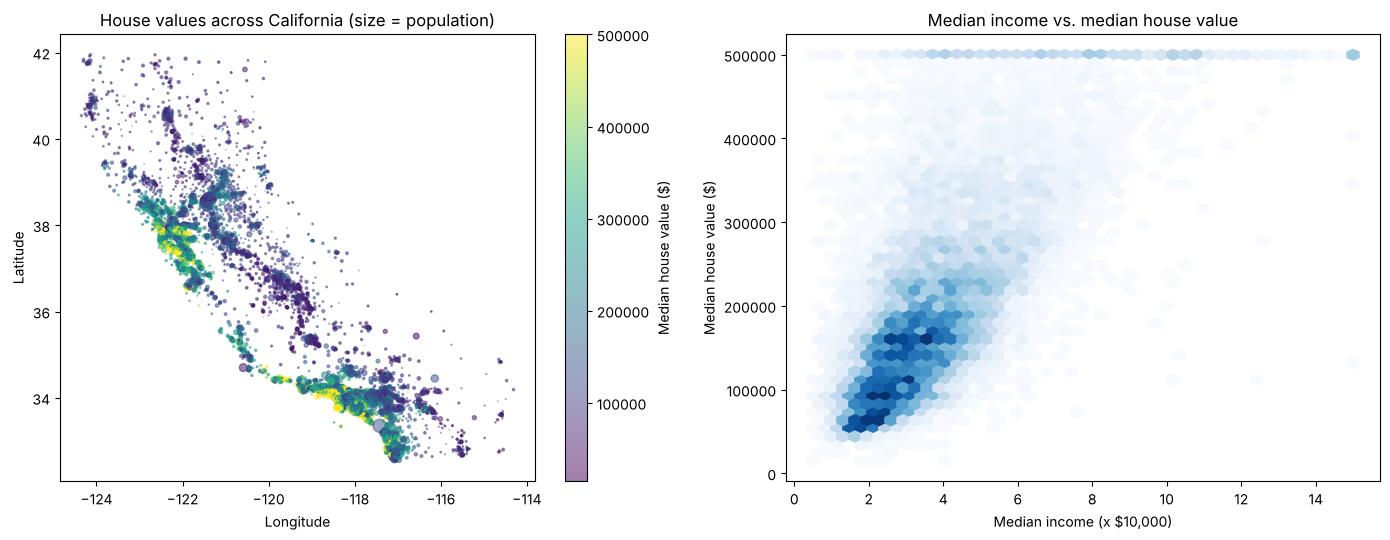

Correlation with median_house_value:
median_income         0.69
total_rooms           0.13
housing_median_age    0.11
households            0.07
total_bedrooms        0.05
population           -0.03
longitude            -0.05
latitude             -0.14


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

points = ax1.scatter(housing["longitude"], housing["latitude"], c=housing["median_house_value"],
                     s=housing["population"] / 400, cmap="viridis", alpha=0.5)
fig.colorbar(points, ax=ax1, label="Median house value ($)")
ax1.set_title("House values across California (size = population)")
ax1.set_xlabel("Longitude"); ax1.set_ylabel("Latitude")

ax2.hexbin(housing["median_income"], housing["median_house_value"], gridsize=45, cmap="Blues", mincnt=1)
ax2.set_title("Median income vs. median house value")
ax2.set_xlabel("Median income (x $10,000)"); ax2.set_ylabel("Median house value ($)")

plt.tight_layout()
plt.show()

print("Correlation with median_house_value:")
print(housing.corr(numeric_only=True)["median_house_value"].drop("median_house_value")
      .sort_values(ascending=False).round(3).to_string())

The map shows the most expensive districts along the coast, especially around **San Francisco Bay** and **Los Angeles**; inland districts are much cheaper. **Median income** is by far the strongest single predictor (correlation ≈ 0.69). The relationship with location is clearly **non-linear** (expensive coastal strips next to cheap inland areas), which a straight-line model cannot capture well from latitude and longitude alone. The horizontal line at the top of the right-hand chart is the \$500,001 cap.

## Step 4: Feature Extraction

The raw totals (`total_rooms`, `population`, ...) mostly measure **how big** a district is, not how expensive its houses are. We therefore extract three **ratio features** that describe the typical home and household:

| New feature | Formula | Meaning |
|---|---|---|
| `rooms_per_household` | total_rooms / households | Size of a typical home |
| `bedrooms_per_room` | total_bedrooms / total_rooms | Low values = larger homes with more non-bedroom rooms |
| `population_per_household` | population / households | Household size / crowding |

These are computed row by row from the same district only, so they do not leak information between folds.

In [8]:
def add_ratio_features(frame):
    frame = frame.copy()
    frame["rooms_per_household"] = frame["total_rooms"] / frame["households"]
    frame["bedrooms_per_room"] = frame["total_bedrooms"] / frame["total_rooms"]
    frame["population_per_household"] = frame["population"] / frame["households"]
    return frame


housing = add_ratio_features(housing)

NUMERIC_FEATURES = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
                    "population", "households", "median_income",
                    "rooms_per_household", "bedrooms_per_room", "population_per_household"]
CATEGORICAL_FEATURES = ["ocean_proximity"]
OUTPUT = "median_house_value"

X = housing[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = housing[OUTPUT]
print(f"Inputs: {X.shape[1]} features ({len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical)")
print(f"Output: {OUTPUT}, mean ${y.mean():,.0f}")
print("\nCorrelation of the new features with the output:")
print(housing[["rooms_per_household", "bedrooms_per_room", "population_per_household", OUTPUT]]
      .corr()[OUTPUT].drop(OUTPUT).round(3).to_string())

Inputs: 12 features (11 numeric + 1 categorical)
Output: median_house_value, mean $206,856

Correlation of the new features with the output:
rooms_per_household         0.15
bedrooms_per_room          -0.26
population_per_household   -0.02


## Step 5: Pre-processing Pipeline

One `ColumnTransformer` is shared by all algorithms:

- **numeric columns:** median imputation (fills the 207 missing `total_bedrooms` and the resulting missing `bedrooms_per_room`) → standard scaling,
- **`ocean_proximity`:** one-hot encoding (`handle_unknown="ignore"` for categories missing from a training fold).

Each algorithm is wrapped as `Pipeline([preprocess, algorithm])`, so the imputer and scaler are **re-fitted on the training folds of every round** and never see the test fold.

In [9]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])
print("Columns after pre-processing:", preprocess.fit(X).transform(X.head()).shape[1])

Columns after pre-processing: 16


## Step 6: The 5 Regression Algorithms

None of these algorithms is used in the instructor's car notebook (Linear Regression, KNN, Decision Tree, Random Forest, Gradient Boosting) or was used in Assignment 2. They cover different ways of handling **non-linear** relationships:

| # | Algorithm | How it works |
|---|---|---|
| 1 | **ElasticNet** | A linear model with a combined **L1 + L2** penalty. It is the linear baseline: every feature has one fixed slope. |
| 2 | **Spline Regression** | `SplineTransformer` replaces every feature by a set of smooth piecewise-cubic curves (6 knots), and a **Bayesian Ridge** model combines them. Each feature can now have a **curved** effect (e.g. value rises with income, but flattens at the top), but features still act independently. |
| 3 | **Nystroem Kernel Regression** | Approximates an **RBF kernel** with 500 random "landmark" districts (`Nystroem`): every district is described by its similarity to the landmarks, then **Bayesian Ridge** is fitted. This captures **interactions** (e.g. location × income) like an SVM/kernel ridge, but scales to 20,000 rows. |
| 4 | **Random Trees Embedding + SGD** | 100 **completely random** trees (depth 8) split the feature space into regions without looking at the output; each district is encoded by the leaves it falls into (a sparse 0/1 vector), and a linear model trained with **Stochastic Gradient Descent** learns a value for every region. |
| 5 | **Stacking Regressor** | Trains algorithms 2, 3 and 4, then a **meta-model** (`RidgeCV` on standardised predictions) learns how much to trust each one, using internal 5-fold predictions so the meta-model never sees predictions made on training data. |

`random_state=42` is fixed everywhere, so the results are reproducible.

**Three details that turned out to matter.** While testing, the Stacking Regressor first produced an RMSE of more than \$900,000 on one fold. Three fixes were needed:

- **SGD needs a scaled output.** Stochastic Gradient Descent takes small steps proportional to the error; with house values in the hundreds of thousands of dollars those steps can become huge and the training *diverges* on some subsets. Algorithm 4 therefore learns a **standardised** output (`TransformedTargetRegressor` with `StandardScaler`) and converts its predictions back to dollars.
- **The Stacking Regressor's internal folds must be shuffled.** `housing.csv` is **sorted by location**, and the default `cv=5` does not shuffle, so each internal fold would leave out a whole region of California. We pass `KFold(5, shuffle=True, random_state=42)` instead.
- **The meta-model needs scaled inputs.** The meta-model receives the three members' predictions, which are numbers around 200,000. With inputs this large, scikit-learn's default `RidgeCV` chose nonsense weights on one fold (about −0.55, −0.01 and −0.05 instead of roughly 0, 0.5 and 0.5), and that fold's RMSE jumped to about \$170,000. Standardising the predictions first (`StandardScaler` → `RidgeCV`) fixes this.

In [10]:
def spline_model():
    return make_pipeline(SplineTransformer(n_knots=6, degree=3), BayesianRidge())


def kernel_model():
    return make_pipeline(Nystroem(kernel="rbf", n_components=500, random_state=42), BayesianRidge())


def tree_embedding_model():
    # SGD is trained on a standardised output (mean 0, std 1); predictions are converted back to dollars
    return TransformedTargetRegressor(
        regressor=make_pipeline(RandomTreesEmbedding(n_estimators=100, max_depth=8, random_state=42),
                                SGDRegressor(random_state=42)),
        transformer=StandardScaler())


algorithms = {
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20_000),
    "Spline Regression": spline_model(),
    "Nystroem Kernel Regression": kernel_model(),
    "Random Trees Embedding + SGD": tree_embedding_model(),
    "Stacking Regressor": StackingRegressor(
        estimators=[("spline", spline_model()), ("kernel", kernel_model()), ("trees", tree_embedding_model())],
        final_estimator=make_pipeline(StandardScaler(), RidgeCV()),
        cv=KFold(n_splits=5, shuffle=True, random_state=42)),
}
for i, name in enumerate(algorithms, 1):
    print(i, name)

1 ElasticNet
2 Spline Regression
3 Nystroem Kernel Regression
4 Random Trees Embedding + SGD
5 Stacking Regressor


## Step 7: 10-Fold Cross Validation

The 10 folds are generated once (`shuffle=True`, `random_state=42`) and stored, so **every algorithm sees exactly the same training and test districts**. Each test fold has about 2,064 districts.

In [11]:
K = 10
FOLDS = list(KFold(n_splits=K, shuffle=True, random_state=42).split(X))

pd.DataFrame([{"fold": f, "train districts": len(tr), "test districts": len(te),
               "mean test value ($)": y.iloc[te].mean(),
               "capped districts in test": int((y.iloc[te] >= 500_000).sum())}
              for f, (tr, te) in enumerate(FOLDS, 1)]).set_index("fold")

,train districts,test districts,mean test value ($),capped districts in test
fold,,,,
1,18576,2064,"206,802.52",95
2,18576,2064,"204,198.10",89
3,18576,2064,"209,089.82",97
4,18576,2064,"210,429.71",124
5,18576,2064,"205,299.85",89
6,18576,2064,"206,776.45",105
7,18576,2064,"207,639.20",104
8,18576,2064,"203,951.40",85
9,18576,2064,"207,723.25",95


## Step 8: Training and Testing

For every algorithm and fold: clone a fresh pipeline → train on 9 folds → predict the 10th → store RMSE, MAE, R² and the predictions.

**Resource usage** is measured per algorithm (over all 10 folds):

| Measurement | How |
|---|---|
| Training / prediction time | `time.perf_counter()` around `fit` and `predict` |
| Average CPU load (%) | `psutil.cpu_percent()` – average load of **all** CPU cores between the start and the end of the algorithm (100% = every core busy) |
| Peak RAM of the process (MB) | `resource.getrusage(...).ru_maxrss` – the highest memory this notebook has used so far |
| GPU memory in use (MB) | `nvidia-smi` after the algorithm (GPU runtime only) – it stays flat if the GPU is not used |

In [12]:
def peak_ram_mb():
    # ru_maxrss is in kilobytes on Linux (Colab)
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024


scores, usage = [], []
predictions = {name: np.empty(len(y)) for name in algorithms}

progress = tqdm(total=len(algorithms) * K, unit="fold")
for name, algorithm in algorithms.items():
    psutil.cpu_percent(interval=None)                      # start a new CPU-load measurement
    fit_total = predict_total = 0.0

    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        progress.set_description(f"{name} [{fold}/{K}]")
        pipeline = Pipeline([("preprocess", clone(preprocess)), ("model", clone(algorithm))])

        t0 = time.perf_counter()
        pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
        t1 = time.perf_counter()
        predicted = pipeline.predict(X.iloc[test_idx])
        t2 = time.perf_counter()

        fit_total += t1 - t0
        predict_total += t2 - t1
        predictions[name][test_idx] = predicted
        actual = y.iloc[test_idx]
        scores.append({"algorithm": name, "fold": fold,
                       "RMSE": root_mean_squared_error(actual, predicted),
                       "MAE": mean_absolute_error(actual, predicted),
                       "R2": r2_score(actual, predicted)})
        progress.update()

    usage.append({"algorithm": name,
                  "train time (s)": fit_total, "predict time (s)": predict_total,
                  "total time (s)": fit_total + predict_total,
                  "avg CPU load (%)": psutil.cpu_percent(interval=None),
                  "peak RAM so far (MB)": peak_ram_mb(),
                  "GPU memory in use (MB)": float(nvidia("memory.used")) if gpu_info else np.nan})
progress.close()

scores = pd.DataFrame(scores)
usage = pd.DataFrame(usage).set_index("algorithm")
print(f"Done: {len(scores)} models trained and tested in {usage['total time (s)'].sum():.0f} s")

  0%|          | 0/50 [00:00<?, ?fold/s]

ElasticNet [1/10]:   0%|          | 0/50 [00:00<?, ?fold/s]

ElasticNet [1/10]:   2%|▏         | 1/50 [00:00<00:07,  6.52fold/s]

ElasticNet [2/10]:   2%|▏         | 1/50 [00:00<00:07,  6.52fold/s]

ElasticNet [2/10]:   4%|▍         | 2/50 [00:00<00:06,  7.86fold/s]

...

Stacking Regressor [9/10]:  98%|█████████▊| 49/50 [02:28<00:12, 12.95s/fold]

Stacking Regressor [10/10]:  98%|█████████▊| 49/50 [02:28<00:12, 12.95s/fold]

Stacking Regressor [10/10]: 100%|██████████| 50/50 [02:41<00:00, 13.06s/fold]

Stacking Regressor [10/10]: 100%|██████████| 50/50 [02:41<00:00,  3.23s/fold]

Done: 50 models trained and tested in 161 s


## Step 9: Results
### Step 9.1: RMSE of every algorithm on every fold

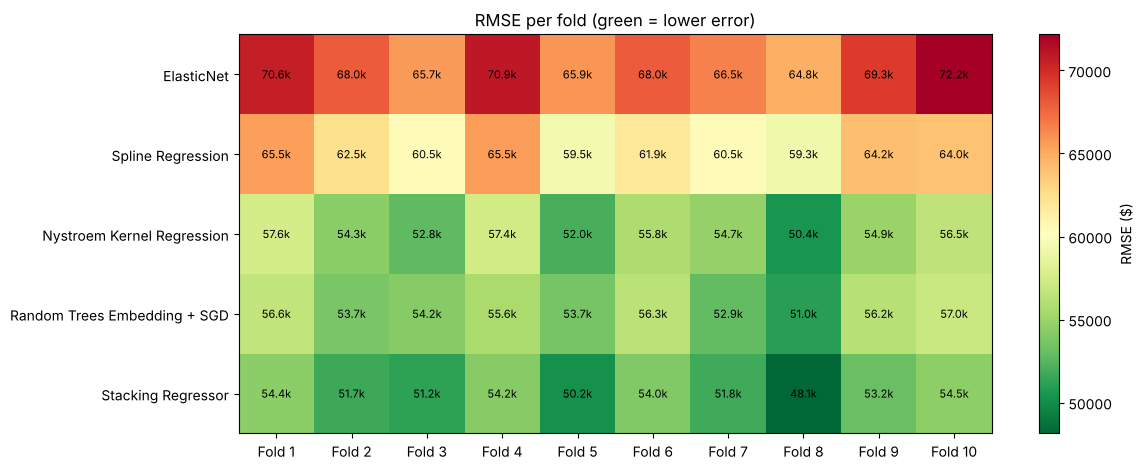

In [13]:
names = list(algorithms)
rmse_table = scores.pivot(index="fold", columns="algorithm", values="RMSE")[names]

fig, ax = plt.subplots(figsize=(12, 4.8))
image = ax.imshow(rmse_table.T.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(K), [f"Fold {f}" for f in rmse_table.index])
ax.set_yticks(range(len(names)), names)
for row in range(len(names)):
    for col in range(K):
        ax.text(col, row, f"{rmse_table.T.values[row, col] / 1000:.1f}k", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="RMSE ($)")
ax.set_title("RMSE per fold (green = lower error)")
plt.tight_layout()
plt.show()

### Step 9.2: Comparison table

The **mean rank** is computed per fold (1 = best on that fold) and then averaged; it shows how consistently an algorithm wins, independent of how large the dollar differences are.

In [14]:
fold_ranks = rmse_table.rank(axis=1)
by_algo = scores.groupby("algorithm")

comparison = pd.DataFrame({
    "RMSE mean ($)": by_algo["RMSE"].mean(),
    "RMSE std ($)": by_algo["RMSE"].std(),
    "MAE mean ($)": by_algo["MAE"].mean(),
    "R2 mean": by_algo["R2"].mean(),
    "mean rank": fold_ranks.mean(),
    "total time (s)": usage["total time (s)"],
}).sort_values("RMSE mean ($)")
comparison.insert(0, "position", np.arange(1, len(comparison) + 1))
comparison.index.name = "algorithm"
ranking = comparison.index.tolist()

comparison.style.format({"RMSE mean ($)": "${:,.0f}", "RMSE std ($)": "${:,.0f}", "MAE mean ($)": "${:,.0f}",
                         "R2 mean": "{:.3f}", "mean rank": "{:.1f}", "total time (s)": "{:.1f}"}) \
    .background_gradient(subset=["RMSE mean ($)"], cmap="Greens_r")

,position,RMSE mean ($),RMSE std ($),MAE mean ($),R2 mean,mean rank,total time (s)
algorithm,,,,,,,
Stacking Regressor,1,"$52,324","$2,108","$35,913",0.794,1.0,135.4
Nystroem Kernel Regression,2,"$54,658","$2,351","$37,825",0.775,2.4,15.1
Random Trees Embedding + SGD,3,"$54,720","$1,938","$38,297",0.775,2.6,5.5
Spline Regression,4,"$62,329","$2,369","$44,618",0.708,4.0,3.9
ElasticNet,5,"$68,191","$2,499","$49,099",0.650,5.0,1.1


### Step 9.3: Where are the errors? (best algorithm)

Out-of-fold predictions of the best algorithm: every district is predicted by a model that did not see it during training.

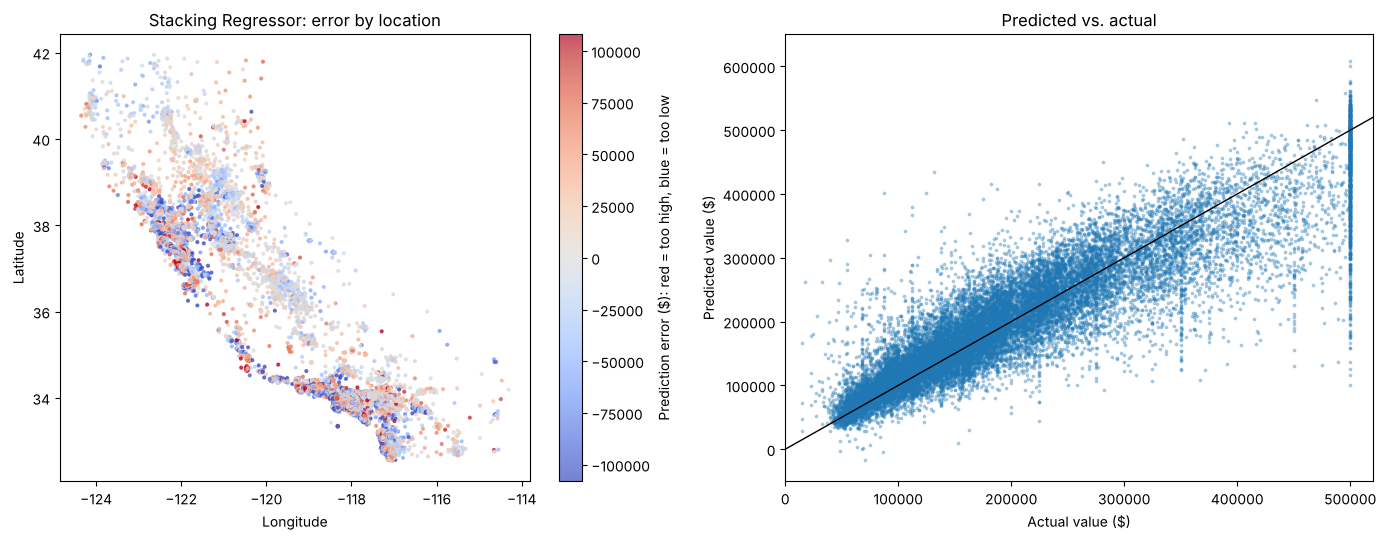

RMSE on capped districts (>= $500,000): $109,237
RMSE on all other districts           : $47,726


In [15]:
best = ranking[0]
residual = predictions[best] - y.values                       # positive = over-estimate

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
limit = np.percentile(np.abs(residual), 95)
spots = ax1.scatter(housing["longitude"], housing["latitude"], c=residual, cmap="coolwarm",
                    vmin=-limit, vmax=limit, s=4, alpha=0.7)
fig.colorbar(spots, ax=ax1, label="Prediction error ($): red = too high, blue = too low")
ax1.set_title(f"{best}: error by location")
ax1.set_xlabel("Longitude"); ax1.set_ylabel("Latitude")

ax2.scatter(y, predictions[best], s=3, alpha=0.3)
ax2.plot([0, 520_000], [0, 520_000], color="black", linewidth=1)
ax2.set_xlim(0, 520_000); ax2.set_ylim(-50_000, 650_000)
ax2.set_xlabel("Actual value ($)"); ax2.set_ylabel("Predicted value ($)")
ax2.set_title("Predicted vs. actual")
plt.tight_layout()
plt.show()

is_capped = y.values >= 500_000
print(f"RMSE on capped districts (>= $500,000): ${np.sqrt(np.mean(residual[is_capped] ** 2)):,.0f}")
print(f"RMSE on all other districts           : ${np.sqrt(np.mean(residual[~is_capped] ** 2)):,.0f}")

### Step 9.4: Time, CPU, memory and GPU

In [16]:
print(f"Run type: {RUN_TYPE} | {psutil.cpu_count()} logical CPUs | GPU: {gpu_info or 'none'}\n")
usage_view = usage.loc[ranking]
if not gpu_info:
    usage_view = usage_view.drop(columns="GPU memory in use (MB)")
usage_view.style.format("{:,.1f}")

Run type: CPU | 4 logical CPUs | GPU: none



,train time (s),predict time (s),total time (s),avg CPU load (%),peak RAM so far (MB)
algorithm,,,,,
Stacking Regressor,134.9,0.5,135.4,79.1,734.4
Nystroem Kernel Regression,14.8,0.3,15.1,90.9,684.9
Random Trees Embedding + SGD,5.2,0.4,5.5,27.2,684.9
Spline Regression,3.8,0.1,3.9,97.9,352.7
ElasticNet,1.0,0.1,1.1,96.7,260.5


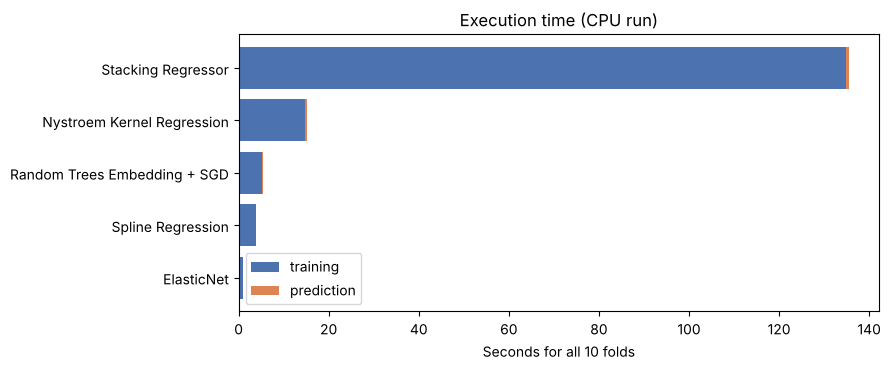

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
times = usage.loc[ranking[::-1]]
ax.barh(times.index, times["train time (s)"], label="training", color="#4c72b0")
ax.barh(times.index, times["predict time (s)"], left=times["train time (s)"], label="prediction", color="#dd8452")
ax.set_xlabel("Seconds for all 10 folds")
ax.set_title(f"Execution time ({RUN_TYPE} run)")
ax.legend()
plt.tight_layout()
plt.show()

#### CPU vs. GPU on Colab

The notebook is run twice on Colab – once on a **CPU** runtime and once on a **T4 GPU** runtime. The cell below saves this run's times as `times_CPU.csv` or `times_GPU.csv` (downloaded automatically on Colab). When both files are present (on Colab you are asked to upload the other one), the next cell compares them.

In [18]:
time_file = f"times_{RUN_TYPE}.csv"
usage[["total time (s)", "avg CPU load (%)", "GPU memory in use (MB)"]].to_csv(time_file)
print("Saved", time_file)
if ON_COLAB:
    colab_files.download(time_file)

Saved times_CPU.csv


In [19]:
if ON_COLAB and not (os.path.isfile("times_CPU.csv") and os.path.isfile("times_GPU.csv")):
    print("Upload the times file of the other run (or cancel):")
    try:
        colab_files.upload()
    except Exception:
        pass

if os.path.isfile("times_CPU.csv") and os.path.isfile("times_GPU.csv"):
    cpu_run = pd.read_csv("times_CPU.csv", index_col=0)
    gpu_run = pd.read_csv("times_GPU.csv", index_col=0)
    cpu_vs_gpu = pd.DataFrame({
        "CPU runtime (s)": cpu_run["total time (s)"],
        "T4 GPU runtime (s)": gpu_run["total time (s)"],
        "GPU memory in use (MB)": gpu_run["GPU memory in use (MB)"],
    }).loc[ranking]
    cpu_vs_gpu["speed-up"] = cpu_vs_gpu["CPU runtime (s)"] / cpu_vs_gpu["T4 GPU runtime (s)"]
    display(cpu_vs_gpu.style.format("{:,.2f}"))
else:
    print("Both times_CPU.csv and times_GPU.csv are needed for the comparison.")

Both times_CPU.csv and times_GPU.csv are needed for the comparison.


#### Colab execution times (filled in from the two runs)

| Algorithm | CPU runtime (s) | T4 GPU runtime (s) | GPU memory in use (MB) | GPU faster? |
|---|---|---|---|---|
| ElasticNet | | | | |
| Spline Regression | | | | |
| Nystroem Kernel Regression | | | | |
| Random Trees Embedding + SGD | | | | |
| Stacking Regressor | | | | |

### Step 9.5: Discussion of the results

> Numbers from the run saved in this notebook. Error values are reproducible (`random_state=42`); times vary between runs and machines.

1. **The Stacking Regressor is the most accurate algorithm**: mean RMSE **≈ \$52,300 ± \$2,100**, MAE ≈ \$35,900, R² ≈ 0.79. It has the lowest RMSE on **all 10 folds** (mean rank 1.0), about **\$2,300 (4%) better** than its best member.
2. **Kernel and tree-embedding methods tie for second place** (Nystroem ≈ \$54,700, Random Trees Embedding + SGD ≈ \$54,700; mean ranks 2.4 and 2.6). Both can model **interactions**, such as "high income *and* near the coast", which is exactly what the map in Step 3.2 shows.
3. **Spline Regression (≈ \$62,300) beats ElasticNet (≈ \$68,200)** because each feature may have a curved effect, but it stays behind the interaction models because every feature still acts *independently*: it cannot learn that latitude matters differently at different longitudes. In the final Stacking model the meta-model gives the spline model almost **no weight** (≈ −0.04, versus ≈ 0.52 for the kernel model and ≈ 0.54 for the tree embedding): it adds nothing the other two do not already know.
4. **ElasticNet is the weakest (R² ≈ 0.65)**: with one fixed slope per feature, latitude and longitude cannot describe California's coast-versus-inland price pattern.
5. **The \$500,001 cap is the largest single source of error.** For the best model, the RMSE on capped districts is **≈ \$109,000**, more than twice the ≈ \$48,000 on all other districts. The error map shows **under-predictions (blue) concentrated along the expensive coast** around San Francisco Bay and Los Angeles, where the true values are "\$500,001 or more" and the model cannot know how much more.
6. **Results are very stable across folds** (standard deviation ≈ \$2,000 – \$2,500, about 4% of the RMSE). With ~2,064 districts per test fold, each fold is a reliable sample, and the Friedman test confirms that the differences between the algorithms are **highly significant (p ≈ 1 × 10⁻⁷)**.
7. **Feature extraction helped interpretation:** `bedrooms_per_room` is more strongly correlated with the house value (≈ −0.26) than any raw count column, i.e. *the proportion of bedrooms* says more about value than the *number* of rooms in the district.
8. **Execution time and resources:** the most accurate model is also by far the slowest – the Stacking Regressor needs ≈ 138 s for 10 folds (≈ 85% of the total), because in every fold it trains each member **six times** (5 internal folds + 1 final fit). Nystroem takes ≈ 15 s, Random Trees Embedding ≈ 5 s, Spline ≈ 4 s and ElasticNet ≈ 1 s. ElasticNet, Spline and Nystroem keep almost all CPU cores busy (≈ 90 – 98% average load, through multi-threaded linear-algebra libraries), while Random Trees Embedding + SGD uses only about one core (≈ 27% of 4 cores), because SGD processes the data one sample at a time. Peak memory stayed below 0.75 GB.
9. **GPU:** scikit-learn runs these algorithms on the CPU only, so the T4 GPU runtime is not expected to speed them up or to use GPU memory; the CPU-vs-GPU table above records what actually happened on Colab. For this problem the time is dominated by repeated CPU training inside Stacking, so a faster CPU (or fewer internal folds) would matter far more than a GPU.

## Step 10: Select and Save the Final Model
### Step 10.1: Are the differences real? (Friedman test)

The **Friedman test** checks whether the five algorithms perform differently across the 10 folds, using their ranks on each fold. A small p-value (< 0.05) means the ranking is not due to chance. We then select the algorithm with the **lowest mean RMSE** and also report its mean rank.

In [20]:
statistic, p_value = friedmanchisquare(*[rmse_table[name] for name in names])
best = ranking[0]
print(f"Friedman test: chi-square = {statistic:.2f}, p = {p_value:.2e} "
      f"({'the algorithms differ significantly' if p_value < 0.05 else 'no significant difference'})")
print(f"\nSelected: {best}")
print(f"  mean RMSE ${comparison.loc[best, 'RMSE mean ($)']:,.0f}, MAE ${comparison.loc[best, 'MAE mean ($)']:,.0f}, "
      f"R2 {comparison.loc[best, 'R2 mean']:.3f}, mean rank {comparison.loc[best, 'mean rank']:.1f}")
print(f"  best on {(rmse_table.idxmin(axis=1) == best).sum()} of {K} folds")

Friedman test: chi-square = 38.08, p = 1.08e-07 (the algorithms differ significantly)

Selected: Stacking Regressor
  mean RMSE $52,324, MAE $35,913, R2 0.794, mean rank 1.0
  best on 10 of 10 folds


### Step 10.2: Train on all 20,640 districts and save

In [21]:
final_pipeline = Pipeline([("preprocess", clone(preprocess)), ("model", clone(algorithms[best]))])
t0 = time.perf_counter()
final_pipeline.fit(X, y)
print(f"{best} trained on all {len(X):,} districts in {time.perf_counter() - t0:.1f} s")

trained = final_pipeline.named_steps["model"]
if hasattr(trained, "final_estimator_"):
    # Meta-model weights converted back to "dollars of prediction per dollar of member prediction"
    scaler, ridge = trained.final_estimator_.steps[0][1], trained.final_estimator_.steps[1][1]
    weights = ridge.coef_ / scaler.scale_
    print("Weight given to each member:", {n: round(float(w), 2) for n, w in zip(trained.named_estimators_, weights)})

with open("california_model.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)

app_info = {
    "student": "Hafiza Rija Gul (FA24-BSE-044)",
    "algorithm": best,
    "rmse": float(comparison.loc[best, "RMSE mean ($)"]),
    "mae": float(comparison.loc[best, "MAE mean ($)"]),
    "r2": float(comparison.loc[best, "R2 mean"]),
    "friedman_p": float(p_value),
    "scikit_learn": sklearn.__version__,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "ocean_proximity": sorted(housing["ocean_proximity"].unique()),
    "medians": {c: float(housing[c].median()) for c in ["housing_median_age", "total_rooms", "total_bedrooms",
                                                         "population", "households", "median_income"]},
    "results": comparison.reset_index()[["position", "algorithm", "RMSE mean ($)", "MAE mean ($)", "R2 mean",
                                         "mean rank"]].round(3).to_dict(orient="records"),
}
with open("app_info.json", "w") as f:
    json.dump(app_info, f, indent=2)

print(f"Saved california_model.pkl ({os.path.getsize('california_model.pkl') / 2**20:.1f} MB) and app_info.json")
print(f"Use scikit-learn=={sklearn.__version__} in requirements.txt")
if ON_COLAB:
    colab_files.download("california_model.pkl")
    colab_files.download("app_info.json")

Stacking Regressor trained on all 20,640 districts in 14.3 s
Weight given to each member: {'spline': -0.04, 'kernel': 0.52, 'trees': 0.54}
Saved california_model.pkl (5.5 MB) and app_info.json
Use scikit-learn==1.6.1 in requirements.txt


## Step 11: Application Phase

A new district is described by its raw attributes; the ratio features are computed with the same function as in Step 4, and the saved pipeline does the rest. Set `TYPE_INPUT = True` to enter your own values.

In [22]:
TYPE_INPUT = False

district = {"longitude": -122.25, "latitude": 37.85, "housing_median_age": 30, "total_rooms": 2500,
            "total_bedrooms": 500, "population": 1200, "households": 450, "median_income": 5.5,
            "ocean_proximity": "NEAR BAY"}

if TYPE_INPUT:
    for key in district:
        raw = input(f"{key} [{district[key]}]: ").strip()
        if raw:
            district[key] = raw if key == "ocean_proximity" else float(raw)

features = add_ratio_features(pd.DataFrame([district]))[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
display(features)

with open("california_model.pkl", "rb") as f:
    model = pickle.load(f)
print(f"Predicted median house value: ${model.predict(features)[0]:,.0f} "
      f"(typical error ±${app_info['mae']:,.0f})")

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity
0,-122.25,37.85,30,2500,500,1200,450,5.50,5.56,0.20,2.67,NEAR BAY


Predicted median house value: $294,167 (typical error ±$35,913)


## Step 12: Deployment

The model is deployed as a **Streamlit** web application (`app.py`) on **Streamlit Community Cloud**:

- `app.py` loads `california_model.pkl` and `app_info.json` once (cached),
- the **Predict** tab takes the district's location (a preset city or exact coordinates, shown on a map), house age, rooms, bedrooms, population, households, median income and ocean proximity, computes the three ratio features and shows the predicted value with its typical error,
- the **Model comparison** tab shows the 10-fold results of all five algorithms,
- `requirements.txt` pins the same scikit-learn version that trained the model.

**Live URL:** see the top of this notebook.

## Step 13: Feedback and Improvements

1. **Handle the \$500,001 cap:** remove capped districts, or treat them separately, so the model is not penalised for values the data cannot express.
2. **Tune the strongest methods** (number of Nystroem components, tree depth, spline knots) with nested cross validation.
3. **Add geographic features** such as distance to the nearest large city or to the coast.
4. **Use more recent data:** the dataset is from the 1990 census, so the dollar values are far below today's prices.

# 3. Conclusion

Five scikit-learn regression algorithms that were not used in the car notebook were compared on the **full California Housing dataset (20,640 districts)** with **10-fold cross validation**, identical folds, identical pre-processing and the same measures (RMSE, MAE, R²):

| Position | Algorithm | RMSE | MAE | R² | Mean rank |
|---|---|---|---|---|---|
| 1 | **Stacking Regressor** | **\$52,324** | **\$35,913** | **0.794** | **1.0** |
| 2 | Nystroem Kernel Regression | \$54,658 | \$37,825 | 0.775 | 2.4 |
| 3 | Random Trees Embedding + SGD | \$54,720 | \$38,297 | 0.775 | 2.6 |
| 4 | Spline Regression | \$62,329 | \$44,618 | 0.708 | 4.0 |
| 5 | ElasticNet | \$68,191 | \$49,099 | 0.650 | 5.0 |

- **Median income and location** determine house values, and the **interaction** between them is what separates the good models from the weak ones.
- The **Stacking Regressor** was selected and deployed: it wins every fold, and the Friedman test shows the differences are significant. Its cost is time: it is ≈ 9× slower than the Nystroem model it improves on.
- Building it correctly required **shuffled internal folds**, a **scaled output for SGD** and a **scaled input for the meta-model** – without them the same algorithm produced a catastrophic error on some folds, which shows why every fold's result has to be checked, not just the average.
- The remaining error is concentrated on districts at the **\$500,001 cap**, a limitation of the data rather than of the algorithms.
- The model is available as a **Streamlit web app** (link at the top of this notebook).